# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

**Student:**Ali iziky

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [3]:
# TASK 1: audit data quality.
print("Dimensions (rows, columns):", df_pe.shape)
print("\nTarget counts:\n", df_pe.Is_Malware.value_counts().rename({0: "benign (0)", 1: "malware (1)"}).to_string())
print("Malware prevalence:", round(df_pe.Is_Malware.mean(), 4))

missing = df_pe.isna().sum()
print("\nMissing values (non-zero only):\n", missing[missing > 0].to_string())

feature_like = df_pe.drop(columns=["SHA256_File_ID"])
print("\nFully duplicated rows:", int(df_pe.duplicated().sum()))
print("Duplicated SHA256_File_ID values:", int(df_pe.SHA256_File_ID.duplicated().sum()))
print("Duplicates ignoring the identifier:", int(feature_like.duplicated().sum()))
print("Unique identifiers / rows:", df_pe.SHA256_File_ID.nunique(), "/", len(df_pe))

display(df_pe.describe().T)

Dimensions (rows, columns): (6000, 15)

Target counts:
 Is_Malware
benign (0)     4389
malware (1)    1611
Malware prevalence: 0.2685

Missing values (non-zero only):
 Import_Count        229
Resource_Entropy    289

Fully duplicated rows: 0
Duplicated SHA256_File_ID values: 0
Duplicates ignoring the identifier: 0
Unique identifiers / rows: 6000 / 6000


,count,mean,std,min,25%,50%,75%,max
Max_Section_Entropy,6000.0,5.709010,1.170152,2.146111,4.821742,5.639862,6.604762,7.990000
Import_Count,5771.0,83.386866,50.301130,0.000000,41.184528,85.663796,120.408591,320.325585
Suspicious_API_Imports,6000.0,2.800167,3.094430,0.000000,1.000000,2.000000,3.000000,24.000000
Has_Valid_Signature,6000.0,0.630833,0.482619,0.000000,0.000000,1.000000,1.000000,1.000000
Has_RWX_Section,6000.0,0.149833,0.356938,0.000000,0.000000,0.000000,0.000000,1.000000
Virtual_to_Raw_Size_Ratio,6000.0,984.890348,9868.008483,0.367195,0.955570,1.129836,1.366755,99999.000000
Resource_Entropy,5711.0,4.535160,1.501097,0.000000,3.483114,4.432941,5.517712,7.990000
Num_Embedded_URLs_IPs,6000.0,1.468333,1.951742,0.000000,0.000000,1.000000,2.000000,11.000000
Abnormal_Compile_Timestamp,6000.0,0.114833,0.318847,0.000000,0.000000,0.000000,0.000000,1.000000
Num_Sections,6000.0,4.758667,1.784551,1.000000,3.000000,5.000000,6.000000,10.000000


Sentinel 99999.0 count: 59 (0.98% of rows)
Sentinel rate by class:
 Is_Malware
0    0.0109
1    0.0068

Ratio without sentinel:
 count    5941.000
mean        1.582
std         1.298
min         0.367
25%         0.953
50%         1.126
75%         1.355
max         6.498

VT detections by class:
             min  max   mean
Is_Malware                 
0             0    2   0.99
1            18   67  42.30
Accuracy of the single rule VT >= 3: 1.0


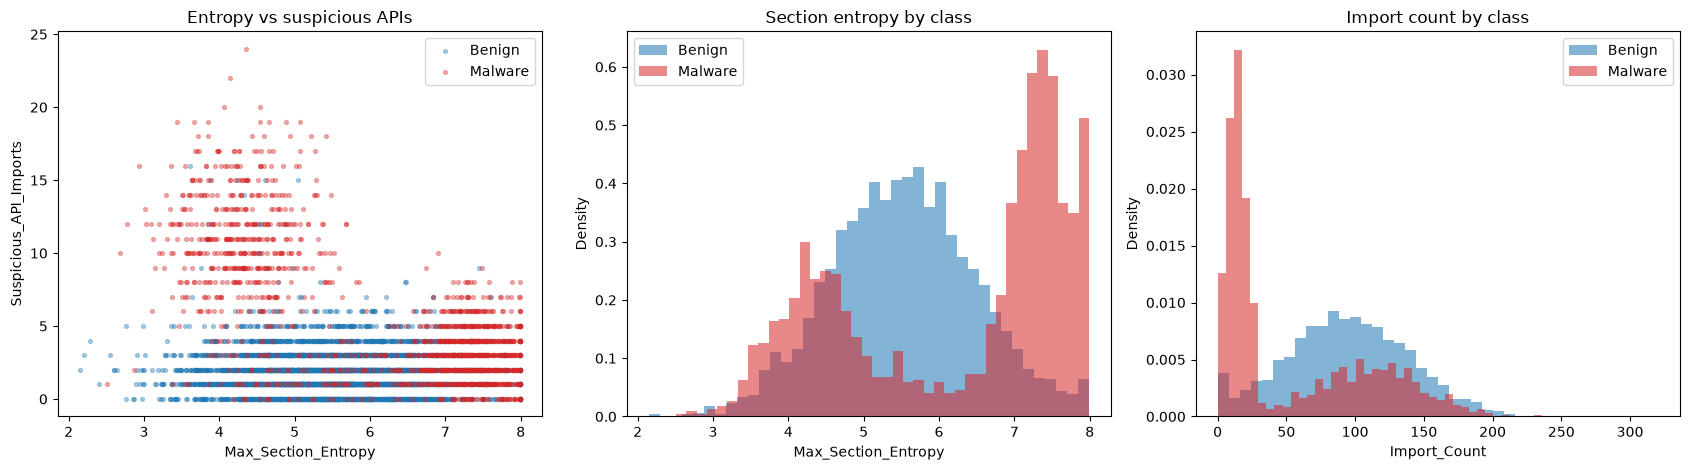

Point-biserial correlation with Is_Malware:
Num_Embedded_URLs_IPs         0.711
Export_Count                 -0.682
Virtual_to_Raw_Size_Ratio     0.620
Resource_Entropy              0.541
Has_RWX_Section               0.527
Suspicious_API_Imports        0.502
Has_Valid_Signature          -0.458
Abnormal_Compile_Timestamp    0.449
Import_Count                 -0.356
Has_TLS_Callback              0.331
Max_Section_Entropy           0.260
Num_Sections                  0.202

Mean feature value by descriptive group:


,Benign,"Malware, entropy < 5.5","Malware, entropy >= 6.5",Other malware (entropy 5.5 to 6.5)
Max_Section_Entropy,5.52,4.33,7.37,5.97
Import_Count,94.25,112.23,15.86,79.38
Suspicious_API_Imports,1.86,9.72,2.99,2.69
Has_Valid_Signature,0.76,0.58,0.04,0.67
Has_RWX_Section,0.04,0.45,0.50,0.13
Virtual_to_Raw_Size_Ratio,1.09,1.07,4.14,1.56
Resource_Entropy,4.04,5.84,6.04,4.36
Num_Embedded_URLs_IPs,0.63,3.53,4.11,1.62
Abnormal_Compile_Timestamp,0.03,0.32,0.39,0.13
Num_Sections,4.54,5.26,5.47,4.69


In [4]:
# TASK 2: inspect the suspicious ratio values and feature distributions.
ratio = df_pe["Virtual_to_Raw_Size_Ratio"]
sentinel = ratio == 99999.0
print("Sentinel 99999.0 count:", int(sentinel.sum()), f"({sentinel.mean():.2%} of rows)")
print("Sentinel rate by class:\n", df_pe.groupby("Is_Malware")["Virtual_to_Raw_Size_Ratio"].apply(lambda s: (s == 99999.0).mean()).round(4).to_string())
print("\nRatio without sentinel:\n", ratio[~sentinel].describe().round(3).to_string())

# Post-scan leakage check (diagnostic only, never a model input).
vt = df_pe["VT_PostScan_Detections"]
print("\nVT detections by class:\n", df_pe.groupby("Is_Malware")["VT_PostScan_Detections"].agg(["min", "max", "mean"]).round(2).to_string())
print("Accuracy of the single rule VT >= 3:", round(((vt >= 3).astype(int) == df_pe.Is_Malware).mean(), 4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
colors = {0: "tab:blue", 1: "tab:red"}
labels = {0: "Benign", 1: "Malware"}
for cls in [0, 1]:
    s = df_pe[df_pe.Is_Malware == cls]
    axes[0].scatter(s.Max_Section_Entropy, s.Suspicious_API_Imports, s=8, alpha=.35, c=colors[cls], label=labels[cls])
    axes[1].hist(s.Max_Section_Entropy, bins=40, alpha=.55, density=True, color=colors[cls], label=labels[cls])
    axes[2].hist(s.Import_Count.dropna(), bins=40, alpha=.55, density=True, color=colors[cls], label=labels[cls])
axes[0].set(xlabel="Max_Section_Entropy", ylabel="Suspicious_API_Imports", title="Entropy vs suspicious APIs")
axes[1].set(xlabel="Max_Section_Entropy", ylabel="Density", title="Section entropy by class")
axes[2].set(xlabel="Import_Count", ylabel="Density", title="Import count by class")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

numeric_for_corr = df_pe.drop(columns=["SHA256_File_ID", "VT_PostScan_Detections"]).copy()
numeric_for_corr.loc[numeric_for_corr.Virtual_to_Raw_Size_Ratio == 99999.0, "Virtual_to_Raw_Size_Ratio"] = np.nan
print("Point-biserial correlation with Is_Malware:")
print(numeric_for_corr.corr()["Is_Malware"].drop("Is_Malware").sort_values(key=np.abs, ascending=False).round(3).to_string())

# Descriptive profiles for the Part B hypotheses (audit only; no feature or model decision is taken from this table).
groups = pd.Series("Other malware (entropy 5.5 to 6.5)", index=numeric_for_corr.index)
groups[numeric_for_corr.Is_Malware == 0] = "Benign"
groups[(numeric_for_corr.Is_Malware == 1) & (numeric_for_corr.Max_Section_Entropy >= 6.5)] = "Malware, entropy >= 6.5"
groups[(numeric_for_corr.Is_Malware == 1) & (numeric_for_corr.Max_Section_Entropy < 5.5)] = "Malware, entropy < 5.5"
profile = numeric_for_corr.drop(columns="Is_Malware").groupby(groups).mean().T
profile.loc["Rows in group"] = groups.value_counts()
print("\nMean feature value by descriptive group:")
display(profile.round(2))

In [5]:
# TASK 3: define the target and clean feature matrix.
DROP_COLS = ["SHA256_File_ID", "VT_PostScan_Detections", "Is_Malware"]
X = df_pe.drop(columns=DROP_COLS).copy()
y = df_pe["Is_Malware"].copy()

# Fixed, stateless parser rule: nothing is learned from the data, so applying it before the split cannot leak.
X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)

FEATURES = list(X.columns)
print("Features:", len(FEATURES), FEATURES)
print("Sentinels remaining:", int((X.Virtual_to_Raw_Size_Ratio == 99999.0).sum()))
print("Missing after sentinel handling:\n", X.isna().sum()[lambda s: s > 0].to_string())

Features: 12 ['Max_Section_Entropy', 'Import_Count', 'Suspicious_API_Imports', 'Has_Valid_Signature', 'Has_RWX_Section', 'Virtual_to_Raw_Size_Ratio', 'Resource_Entropy', 'Num_Embedded_URLs_IPs', 'Abnormal_Compile_Timestamp', 'Num_Sections', 'Has_TLS_Callback', 'Export_Count']
Sentinels remaining: 0
Missing after sentinel handling:
 Import_Count                 229
Virtual_to_Raw_Size_Ratio     59
Resource_Entropy             289


## Answers: Part A (forensic audit and problem formulation)

**A1. Observed.** The dataset has 6,000 rows and 15 columns: 4,389 benign and 1,611 malware, a prevalence of 26.85%. Missing values are `Import_Count` 229 and `Resource_Entropy` 289. There are 0 duplicated rows and 0 duplicated identifiers. `Virtual_to_Raw_Size_Ratio` contains 59 sentinel values of 99999.0 (0.98% of rows).

**A2. Data-quality and governance risks.**
- **Parser sentinel.** The sentinel raises the ratio's mean to 984.89, against 1.58 without it (maximum 6.50). It is an error code, not a measurement. I replaced it with `NaN` and let the fold-fitted median imputer handle it. Rows are kept because a production parser will also fail sometimes and those files still need a score. The sentinel rate is similar across classes (1.09% benign, 0.68% malware), so I did not add a missingness flag.
- **Post-scan leakage.** `VT_PostScan_Detections` ranges 0 to 2 for benign and 18 to 67 for malware. The single rule `VT >= 3` reaches accuracy 1.0. This value is recorded after the event and does not exist at first inspection, so a model using it would look perfect and be unusable.
- **Identifier.** `SHA256_File_ID` is unique for all 6,000 rows. It carries no generalizable file property, a new file has an unseen hash, and a model could only memorize it.
- **Label noise.** The supplied generator flips 4% of labels, so a fixed fraction of labels contradicts the file profile.

**A3. Problem statement.** Binary classification of one Windows PE file per prediction. The target is `Is_Malware`, and the positive class is malware (1). The decision is made at pre-execution static inspection, using only the 12 static features available then. The output is a ranked suspicion score with a recommended review flag, used by SOC analysts. It does not declare a file malicious or block it.

**A4. Prevalence.** The 26.85% rate is a parameter of the synthetic generator (25% before label flips). It says nothing about AtlasPay's traffic. Two operational consequences of a lower or changing base rate:
1. Precision falls at the same error rates. In the sensitivity table, precision is 0.243 at 0.5% prevalence and 0.060 at 0.1%.
2. Alert volume becomes dominated by false positives, and a threshold tuned at one base rate is no longer cost-optimal at another.

## Answers: Part B (feature forensics and threat hypotheses)

**B1. Observed in the projection.** Benign files concentrate at low `Suspicious_API_Imports` (mostly 0 to 5) with entropy centred near 5.5. Malware forms two visible concentrations: high entropy (about 6.5 to 8) with few suspicious APIs, and lower entropy (about 3 to 5.5) with many suspicious APIs (up to 24). No single straight line in this plane separates both malware groups from benign files.

**Limit of that observation.** This is 2 of 12 features, so it does not prove the full problem is non-linear. In fact, Logistic Regression reaches validation F1 0.9238 using all features, and `Num_Embedded_URLs_IPs` (r = 0.711) and `Export_Count` (r = -0.682) separate the classes almost monotonically. `Max_Section_Entropy` has only r = 0.260 because its two malware groups pull in opposite directions.

**B2. Two hypotheses (group means from the audit table; groups were cut by me on entropy, so they are descriptive).**

| | H1: packed or obfuscated-like (entropy >= 6.5, n = 948) | H2: API-rich and not high-entropy (entropy < 5.5, n = 572) |
|---|---|---|
| Supporting features | Entropy 7.37, imports 15.86, valid signature 0.04, size ratio 4.14 | Entropy 4.33, imports 112.23, suspicious APIs 9.72, RWX 0.45 |
| Benign comparison | Entropy 5.52, imports 94.25, signature 0.76, ratio 1.09 | Suspicious APIs 1.86, RWX 0.04 |
| Alternative explanation | Legitimate installers, compressed resources or DRM protectors also show high entropy and few imports | Administration, debugging and security tools legitimately import sensitive APIs |
| Limitation | A label flip can place benign files in this group | 0.58 valid signature shows that signing does not separate this group, and the data cannot say why |

**B3. Limits of static evidence.** Entropy measures byte distribution, and compressed media looks like encrypted data. Few imports may suggest packing but do not show an unpacking stub. An import shows that a function can be resolved, not that it runs or why. Intent is not a file property. **Independent validation:** detonate the file in an instrumented sandbox and look for runtime unpacking into memory, process injection, persistence, and command-and-control traffic, then compare that behaviour with the static hypothesis.

## Phase 2 — Design a leakage-safe evaluation protocol

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test`.
2. Define a preprocessing pipeline with median imputation. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.
3. Build candidate pipelines:
   - Logistic Regression (linear baseline)
   - Deep Decision Tree (single white-box tree)
   - Random Forest (bagging)
   - LightGBM if installed; otherwise `HistGradientBoostingClassifier` and label it accurately (not LightGBM).
4. Use the same CV folds and report train F1, validation F1, PR-AUC and fit time.
5. Interpret bias/variance and choose candidates worth further investigation.

In [6]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=.20, stratify=y, random_state=SEED)
print("Development:", X_dev.shape, "prevalence", round(y_dev.mean(), 4))
print("Lockbox test:", X_test.shape, "prevalence", round(y_test.mean(), 4))

# LightGBM when installed; otherwise the explicitly named scikit-learn fallback.
try:
    from lightgbm import LGBMClassifier
    BOOST_NAME = "LightGBM"
    def make_boost():
        return LGBMClassifier(n_estimators=300, learning_rate=.05, num_leaves=31, random_state=SEED, verbose=-1)
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    BOOST_NAME = "HistGradientBoosting (fallback, not LightGBM)"
    def make_boost():
        return HistGradientBoostingClassifier(max_iter=300, learning_rate=.05, max_leaf_nodes=31,
                                              early_stopping=False, random_state=SEED)
print("Boosting implementation:", BOOST_NAME)

def imputer():
    return SimpleImputer(strategy="median")

def make_lr():
    return Pipeline([("imputer", imputer()), ("scaler", RobustScaler()),
                     ("clf", LogisticRegression(max_iter=3000, random_state=SEED))])
def make_tree():
    return Pipeline([("imputer", imputer()), ("clf", DecisionTreeClassifier(max_depth=None, random_state=SEED))])
def make_rf():
    return Pipeline([("imputer", imputer()), ("clf", RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=SEED))])
def make_boost_pipe():
    return Pipeline([("imputer", imputer()), ("clf", make_boost())])

candidates = {"Logistic Regression": make_lr(), "Decision Tree (deep)": make_tree(),
              "Random Forest": make_rf(), BOOST_NAME: make_boost_pipe()}

Development: (4800, 12) prevalence 0.2685
Lockbox test: (1200, 12) prevalence 0.2683
Boosting implementation: HistGradientBoosting (fallback, not LightGBM)


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Heterogeneous stacking: every base learner keeps its own fold-safe pipeline.
candidates["Stacking (LR + RF + Boosting)"] = StackingClassifier(
    estimators=[("lr", make_lr()), ("rf", make_rf()), ("boost", make_boost_pipe())],
    final_estimator=LogisticRegression(max_iter=3000, random_state=SEED),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), stack_method="predict_proba")

scoring = {"f1": "f1", "ap": "average_precision"}
rows = []
for name, model in candidates.items():
    t0 = time.perf_counter()
    r = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring, return_train_score=True, n_jobs=1)
    rows.append({"Model": name,
                 "Train F1": r["train_f1"].mean(), "Val F1": r["test_f1"].mean(), "Val F1 SD": r["test_f1"].std(),
                 "Train-Val F1 gap": r["train_f1"].mean() - r["test_f1"].mean(),
                 "Train PR-AUC": r["train_ap"].mean(), "Val PR-AUC": r["test_ap"].mean(), "Val PR-AUC SD": r["test_ap"].std(),
                 "Mean fit time (s)": r["fit_time"].mean(), "Total CV wall time (s)": time.perf_counter() - t0})
    print(f"done: {name}")
cv_table = pd.DataFrame(rows).set_index("Model").sort_values("Val PR-AUC", ascending=False)
display(cv_table.round(4))

done: Logistic Regression


done: Decision Tree (deep)


done: Random Forest


done: HistGradientBoosting (fallback, not LightGBM)


done: Stacking (LR + RF + Boosting)


,Train F1,Val F1,Val F1 SD,Train-Val F1 gap,Train PR-AUC,Val PR-AUC,Val PR-AUC SD,Mean fit time (s),Total CV wall time (s)
Model,,,,,,,,,
Stacking (LR + RF + Boosting),0.9506,0.9241,0.0089,0.0265,0.9977,0.9100,0.0198,12.9726,67.4487
Logistic Regression,0.9231,0.9238,0.0084,-0.0007,0.9102,0.9080,0.0228,0.0236,0.2459
Random Forest,1.0000,0.9237,0.0091,0.0763,1.0000,0.9054,0.0165,1.8998,11.7833
"HistGradientBoosting (fallback, not LightGBM)",0.9973,0.9205,0.0080,0.0767,1.0000,0.9042,0.0204,0.6838,4.1467
Decision Tree (deep),1.0000,0.8301,0.0135,0.1699,1.0000,0.7330,0.0205,0.0530,0.4193


### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:
1. Which model shows the largest train–validation gap? What does it suggest?
2. Does the linear baseline already perform competitively?
3. Does Random Forest improve on the single tree?
4. Does boosting improve PR-AUC enough to justify its complexity?
5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

## Answers: Checkpoint 1 and Part C (leakage-safe model comparison)

**Why scaling is only used for Logistic Regression.** Trees split on feature order, so monotonic rescaling leaves their partitions unchanged. `RobustScaler` conditions the linear solver and uses median and IQR, which limits the effect of remaining outliers.

**C1 (observed, 5-fold CV on the development set).**

| Model | Train F1 | Val F1 | F1 gap | Val PR-AUC (SD) | Mean fit (s) |
|---|---|---|---|---|---|
| Stacking (LR + RF + Boosting) | 0.9506 | 0.9241 | 0.0265 | 0.9100 (0.0198) | 12.97 |
| Logistic Regression | 0.9231 | 0.9238 | -0.0007 | 0.9080 (0.0228) | 0.02 |
| Random Forest | 1.0000 | 0.9237 | 0.0763 | 0.9054 (0.0165) | 1.90 |
| HistGradientBoosting (fallback, not LightGBM) | 0.9973 | 0.9205 | 0.0767 | 0.9042 (0.0204) | 0.68 |
| Decision Tree (deep) | 1.0000 | 0.8301 | 0.1699 | 0.7330 (0.0205) | 0.05 |

LightGBM is not installed in this environment, so the documented fallback was used.

**C2 (and checkpoint 1).** The deep Decision Tree shows the clearest overfitting: train F1 1.0000, validation F1 0.8301, gap 0.1699. It has memorized the training folds, including noisy labels.

**Checkpoint 2.** Yes. Logistic Regression is competitive, with validation F1 0.9238 and PR-AUC 0.9080, and essentially no gap.

**Checkpoint 3.** Yes. Random Forest improves strongly on the single tree (PR-AUC 0.9054 against 0.7330). Averaging reduces variance, although its train F1 of 1.0 still shows it fits the training data fully.

**Checkpoint 4.** No. Boosting has PR-AUC 0.9042, slightly below Logistic Regression, so its complexity is not justified by this measurement.

**Checkpoint 5.** No. Stacking gains 0.0020 PR-AUC over Logistic Regression, well inside the fold SD of about 0.02, at about 13 s per fit against 0.02 s and with three models to maintain.

**C3. No unique best model is established.** Comparing two candidates:
- **Logistic Regression:** PR-AUC 0.9080, F1 0.9238, gap -0.0007, fit 0.02 s, inspectable coefficients, one simple artifact to deploy.
- **Random Forest:** PR-AUC 0.9054, F1 0.9237, gap 0.0763, fit 1.90 s, supports TreeSHAP and threshold-style interactions, but is a larger artifact.

The four strong candidates differ by 0.0058 PR-AUC at most, about a quarter of one fold SD.

**Hypothesis on why they tie.** Precision sits near 0.96 until recall near 0.89, then collapses. The generator flips 4% of labels, which predicts about 144 benign-to-malware and 48 malware-to-benign flips in 4,800 development rows. Logistic Regression has 142 OOF false negatives and 49 false positives at its triage threshold. This match is consistent with models reaching a label-noise ceiling. I did not verify it row by row.

**C4.** A small PR-AUC difference is within sampling variation here and PR-AUC averages over all thresholds, while deployment uses one. Maintenance, latency, explainability and failure behaviour can matter more than a difference this size.

**C5.** The lockbox gives one final estimate that was not used for selection or tuning. Learned preprocessing must be fitted inside each training fold, otherwise medians and IQRs would use validation rows and inflate the validation estimate.

**Shortlist for later phases:** Logistic Regression, Random Forest and the boosting fallback. Stacking and the single tree are excluded for the reasons above.

In [8]:
import os, platform, sklearn
SHORTLIST = ["Logistic Regression", "Random Forest", BOOST_NAME]
# Tree used for forensics/SHAP: the better tree ensemble by development CV PR-AUC. Fixed before any test-set use.
TREE_NAME = cv_table.loc[["Random Forest", BOOST_NAME], "Val PR-AUC"].idxmax()
print("Shortlist:", SHORTLIST, "| tree model for forensics:", TREE_NAME)

fitted, latency_rows = {}, []
batch = X_dev.sample(1000, random_state=SEED)  # latency uses development rows; labels play no role
for name in SHORTLIST + ["Stacking (LR + RF + Boosting)"]:
    m = clone(candidates[name])
    t0 = time.perf_counter(); m.fit(X_dev, y_dev); fit_s = time.perf_counter() - t0
    fitted[name] = m
    times = []
    for _ in range(30):
        t0 = time.perf_counter(); m.predict_proba(batch); times.append((time.perf_counter() - t0) * 1000)
    single = []
    for i in range(50):
        t0 = time.perf_counter(); m.predict_proba(batch.iloc[[i]]); single.append((time.perf_counter() - t0) * 1000)
    latency_rows.append({"Model": name, "Refit on X_dev (s)": fit_s,
                         "Median ms / 1,000 files": np.median(times), "P95 ms / 1,000 files": np.percentile(times, 95),
                         "Median ms / single file": np.median(single)})
latency_table = pd.DataFrame(latency_rows).set_index("Model")
display(latency_table.round(2))
print(f"Runtime: {platform.platform()} | {platform.processor()} | logical CPUs={os.cpu_count()} | scikit-learn {sklearn.__version__}")
print("Scope: in-process predict_proba on an already parsed feature table, in a notebook on this machine.")
print("Excludes: PE parsing, feature extraction, I/O, queueing, network and service overhead.")

Shortlist: ['Logistic Regression', 'Random Forest', 'HistGradientBoosting (fallback, not LightGBM)'] | tree model for forensics: Random Forest


,Refit on X_dev (s),"Median ms / 1,000 files","P95 ms / 1,000 files",Median ms / single file
Model,,,,
Logistic Regression,0.02,1.29,2.67,1.19
Random Forest,1.78,47.65,69.14,18.45
"HistGradientBoosting (fallback, not LightGBM)",0.59,13.53,17.23,4.63
Stacking (LR + RF + Boosting),15.28,70.27,78.06,31.55


Runtime: Windows-11-10.0.26300-SP0 | Intel64 Family 6 Model 140 Stepping 1, GenuineIntel | logical CPUs=8 | scikit-learn 1.9.1
Scope: in-process predict_proba on an already parsed feature table, in a notebook on this machine.
Excludes: PE parsing, feature extraction, I/O, queueing, network and service overhead.


### Latency reading (observed)

Median time for 1,000 files: Logistic Regression 1.29 ms, boosting fallback 13.53 ms, Random Forest 47.65 ms, Stacking 70.27 ms. Single-file median: 1.19, 4.63, 18.45 and 31.55 ms. Random Forest runs single-threaded here (`n_jobs=1`), because the threaded version flooded the notebook with joblib warnings. Timings vary between runs on this laptop, so only the order of magnitude should be read.

## Phase 3 — Error forensics: investigate a real disagreement

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [9]:
# Models were fitted on X_dev only (previous cell). threshold=0.50 is for this diagnostic only.
DIAG_THRESHOLD = 0.50
test_proba = {name: fitted[name].predict_proba(X_test)[:, 1] for name in SHORTLIST}
lr_p, tree_p = test_proba["Logistic Regression"], test_proba[TREE_NAME]
lr_pred, tree_pred = (lr_p >= DIAG_THRESHOLD).astype(int), (tree_p >= DIAG_THRESHOLD).astype(int)
y_true = y_test.to_numpy()

print("Agreement structure at the diagnostic threshold (test rows):")
display(pd.crosstab([pd.Series(y_true, name="y_true")], [pd.Series(lr_pred, name="LR_pred"), pd.Series(tree_pred, name="Tree_pred")]))

target_mask = (y_true == 1) & (lr_pred == 0) & (tree_pred == 1)
print("Malware with LR=benign and tree=malware:", int(target_mask.sum()))
if target_mask.sum() == 0:
    print("No such observation exists; falling back to the largest disagreement of any kind.")
    target_mask = lr_pred != tree_pred
pos_idx = np.where(target_mask)[0]
case_pos = pos_idx[np.argmax(np.abs(tree_p[pos_idx] - lr_p[pos_idx]))]
case_idx = X_test.index[case_pos]

# Verification: never tell the story before these assertions pass.
assert y_test.loc[case_idx] == y_true[case_pos]
case_summary = {"Original row index": int(case_idx), "SHA256_File_ID": df_pe.loc[case_idx, "SHA256_File_ID"],
                "True label (Is_Malware)": int(y_true[case_pos]), "Threshold used (both models)": DIAG_THRESHOLD,
                "Logistic Regression P(malware)": round(float(lr_p[case_pos]), 4), "Logistic Regression class": int(lr_pred[case_pos]),
                f"{TREE_NAME} P(malware)": round(float(tree_p[case_pos]), 4), "Tree class": int(tree_pred[case_pos])}
for k, v in case_summary.items(): print(f"{k}: {v}")

context = pd.DataFrame({"Case value": X_test.loc[case_idx],
                        "Dev median benign": X_dev[y_dev == 0].median(), "Dev median malware": X_dev[y_dev == 1].median()})
display(context.round(3))

Agreement structure at the diagnostic threshold (test rows):


LR_pred      0     1     
Tree_pred    0  1  0    1
y_true                   
0          869  1  0    8
1           34  2  1  285

Malware with LR=benign and tree=malware: 2
Original row index: 5115
SHA256_File_ID: sha256_05115_pe
True label (Is_Malware): 1
Threshold used (both models): 0.5
Logistic Regression P(malware): 0.4265
Logistic Regression class: 0
Random Forest P(malware): 0.9667
Tree class: 1


,Case value,Dev median benign,Dev median malware
Max_Section_Entropy,7.221,5.530,6.959
Import_Count,13.185,93.811,21.770
Suspicious_API_Imports,1.000,2.000,4.000
Has_Valid_Signature,0.000,1.000,0.000
Has_RWX_Section,0.000,0.000,0.000
Virtual_to_Raw_Size_Ratio,2.331,1.070,2.430
Resource_Entropy,5.381,4.063,6.010
Num_Embedded_URLs_IPs,1.000,0.000,4.000
Abnormal_Compile_Timestamp,0.000,0.000,0.000
Num_Sections,10.000,5.000,5.000


shap 0.54.1


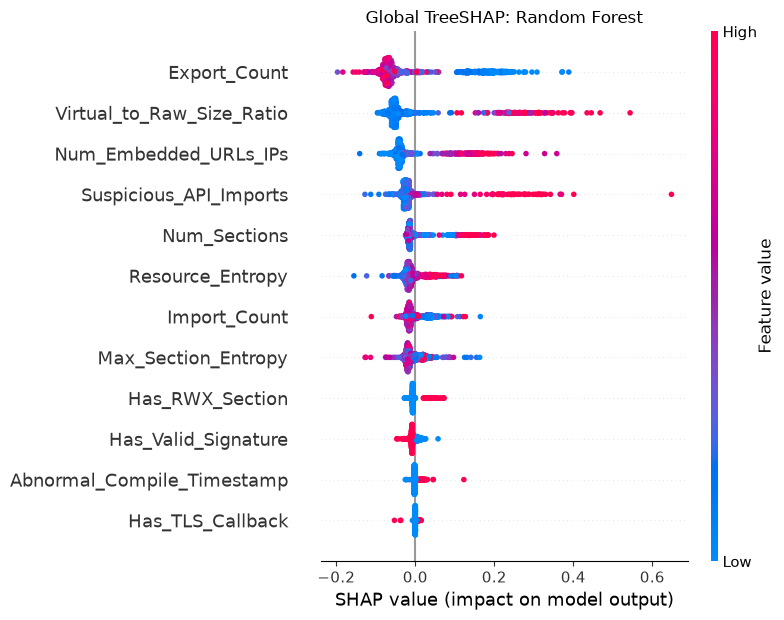

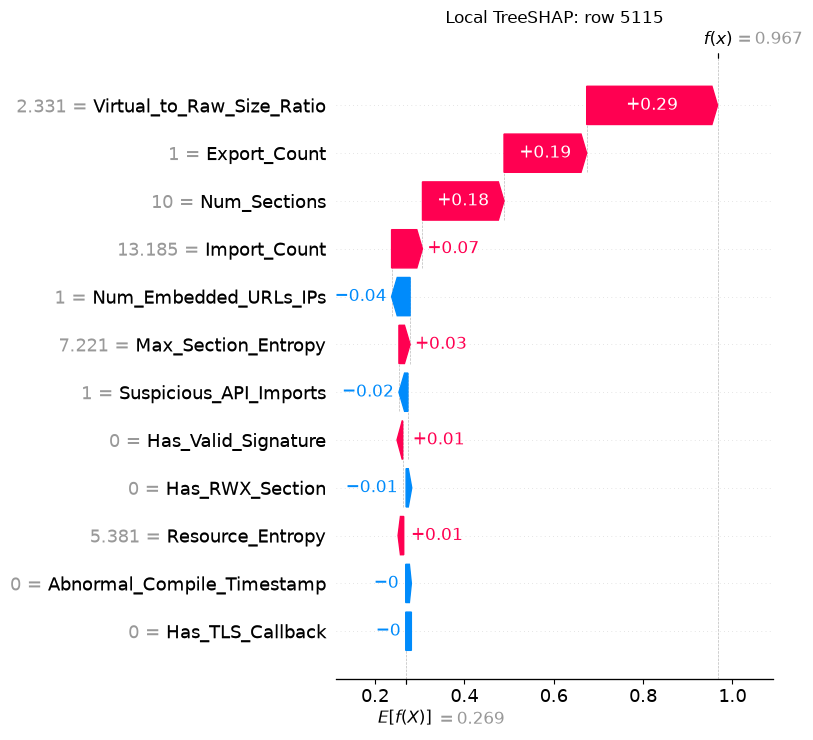

,Imputed feature value,SHAP value
Virtual_to_Raw_Size_Ratio,2.3310,0.2930
Export_Count,1.0000,0.1850
Num_Sections,10.0000,0.1826
Import_Count,13.1845,0.0691
Max_Section_Entropy,7.2215,0.0250
Has_Valid_Signature,0.0000,0.0117
Resource_Entropy,5.3814,0.0053
Has_TLS_Callback,0.0000,-0.0000
Abnormal_Compile_Timestamp,0.0000,-0.0045
Has_RWX_Section,0.0000,-0.0077


Three largest positive: {'Virtual_to_Raw_Size_Ratio': 0.293, 'Export_Count': 0.185, 'Num_Sections': 0.1826}
Two largest negative: {'Num_Embedded_URLs_IPs': -0.0414, 'Suspicious_API_Imports': -0.02}
Base value 0.2686 + sum(SHAP) = 0.9667
Explained output: predicted probability. Model P(malware) = 0.9667


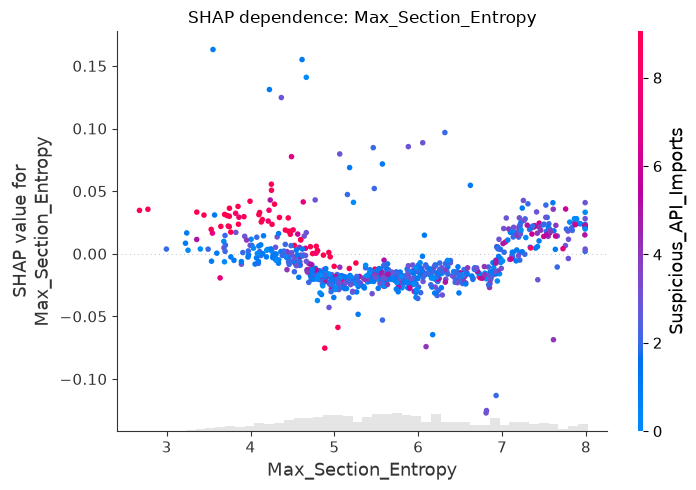

In [10]:
import shap
print("shap", shap.__version__)
tree_pipe = fitted[TREE_NAME]
tree_imputer, tree_clf = tree_pipe.named_steps["imputer"], tree_pipe.named_steps["clf"]
def impute_df(frame):
    return pd.DataFrame(tree_imputer.transform(frame), columns=FEATURES, index=frame.index)
def positive_class(expl):
    return expl[..., 1] if expl.values.ndim == 3 else expl

explainer = shap.TreeExplainer(tree_clf)
# Global view on development rows, so the lockbox is not mined for global patterns.
X_global = impute_df(X_dev.sample(800, random_state=SEED))
sv_global = positive_class(explainer(X_global))
plt.figure(); shap.plots.beeswarm(sv_global, max_display=12, show=False)
plt.title(f"Global TreeSHAP: {TREE_NAME}"); plt.tight_layout(); plt.show()

X_case = impute_df(X_test.loc[[case_idx]])
sv_case = positive_class(explainer(X_case))[0]
plt.figure(); shap.plots.waterfall(sv_case, max_display=12, show=False)
plt.title(f"Local TreeSHAP: row {case_idx}"); plt.tight_layout(); plt.show()

shap_table = pd.DataFrame({"Imputed feature value": X_case.iloc[0], "SHAP value": sv_case.values}, index=FEATURES).sort_values("SHAP value", ascending=False)
display(shap_table.round(4))
print("Three largest positive:", shap_table.head(3)["SHAP value"].round(4).to_dict())
print("Two largest negative:", shap_table.sort_values("SHAP value").head(2)["SHAP value"].round(4).to_dict())

margin = float(sv_case.base_values + sv_case.values.sum())
model_p = float(tree_pipe.predict_proba(X_test.loc[[case_idx]])[0, 1])
print(f"Base value {float(sv_case.base_values):.4f} + sum(SHAP) = {margin:.4f}")
if TREE_NAME == "Random Forest":
    print(f"Explained output: predicted probability. Model P(malware) = {model_p:.4f}")
else:
    print(f"Explained output: raw log-odds. Model P(malware) = {model_p:.4f}; logit(P) = {np.log(model_p / (1 - model_p)):.4f}")

shap.plots.scatter(sv_global[:, "Max_Section_Entropy"], color=sv_global[:, "Suspicious_API_Imports"], show=False)
plt.title("SHAP dependence: Max_Section_Entropy"); plt.tight_layout(); plt.show()

In [11]:
# Logistic Regression explanation (model-level, fitted on X_dev only). SHAP above explains the tree model, not this one.
lr_pipe = fitted["Logistic Regression"]
lr_scaler, lr_clf = lr_pipe.named_steps["scaler"], lr_pipe.named_steps["clf"]
coef_table = pd.DataFrame({"Coefficient (per IQR, log-odds)": lr_clf.coef_[0], "Odds ratio per IQR": np.exp(lr_clf.coef_[0]),
                           "IQR used by scaler": lr_scaler.scale_}, index=FEATURES).sort_values("Coefficient (per IQR, log-odds)", key=np.abs, ascending=False)
display(coef_table.round(3))
print("Intercept (log-odds):", round(float(lr_clf.intercept_[0]), 3))
print("Binary features with IQR 1 are per 0-to-1 change; a zero IQR is replaced by 1 by RobustScaler.")

,"Coefficient (per IQR, log-odds)",Odds ratio per IQR,IQR used by scaler
Export_Count,-1.183,0.306,6.000
Has_RWX_Section,0.859,2.360,1.000
Abnormal_Compile_Timestamp,0.821,2.272,1.000
Num_Embedded_URLs_IPs,0.725,2.065,2.000
Suspicious_API_Imports,0.521,1.683,2.000
Has_Valid_Signature,-0.419,0.658,1.000
Has_TLS_Callback,0.411,1.509,1.000
Virtual_to_Raw_Size_Ratio,0.337,1.401,0.403
Resource_Entropy,0.325,1.384,1.912
Import_Count,-0.172,0.842,74.657


Intercept (log-odds): -2.767
Binary features with IQR 1 are per 0-to-1 change; a zero IQR is replaced by 1 by RobustScaler.


## Answers: Part D (error forensics and local explanation)

**D1 (observed).** At the diagnostic threshold 0.50, 2 of 322 test malware files were benign for Logistic Regression and malware for Random Forest. The largest-gap case is:

| Row | ID | True label | LR P(malware) | LR class | RF P(malware) | RF class | Threshold |
|---|---|---|---|---|---|---|---|
| 5115 | `sha256_05115_pe` | 1 (malware) | 0.4265 | 0 | 0.9667 | 1 | 0.50 for both |

**D2. Observed values (development malware and benign medians in brackets).** `Max_Section_Entropy` 7.221 (6.959 / 5.530), `Import_Count` 13.185 (21.770 / 93.811), unsigned, size ratio 2.331 (2.430 / 1.070), `Export_Count` 1 (1 / 7), `Num_Sections` 10 (5 / 5). Against that, `Suspicious_API_Imports` is 1 (4 / 2), `Num_Embedded_URLs_IPs` is 1 (4 / 0), and RWX, TLS and timestamp flags are all 0.

**Interpretation.** Logistic Regression adds independent weighted evidence, and several of its strongest positive signals are absent here (RWX +0.859, timestamp +0.821, URLs +0.725 log-odds per IQR). Its `Max_Section_Entropy` coefficient is close to zero (-0.110), which fits a variable that points in opposite directions for the two malware groups. The forest can use the feature combination (high ratio, few exports, many sections) through conditional splits. The profile looks like hypothesis H1 from Part B, but that is a hypothesis about the file, not a finding.

**D3 (observed, Random Forest, output is predicted probability, base value 0.2686, final 0.9667).**
- Three largest positive: `Virtual_to_Raw_Size_Ratio` +0.2930, `Export_Count` +0.1850, `Num_Sections` +0.1826.
- Two largest negative: `Num_Embedded_URLs_IPs` -0.0414, `Suspicious_API_Imports` -0.0200.

Global beeswarm (800 development rows): `Export_Count`, the size ratio, URLs and suspicious APIs dominate. Low exports and high ratios raise the output. `Max_Section_Entropy` ranks only eighth, possibly because correlated features (ratio, imports) share its credit.

**D4.** A positive SHAP value means that feature's value moved this model's output for this file above the base value, given the explainer's background. It describes how the model computes its score. It is not causal: no feature was intervened on, correlated features share credit, and the model can be wrong or learn from noisy labels. It also says nothing about the file's real behaviour, so it cannot prove maliciousness. Note that the SHAP values explain Random Forest, while Logistic Regression is explained by its coefficient table.

**D5. Next investigative action.** Detonate `sha256_05115_pe` in a sandbox and inspect its 10 sections for runtime unpacking. Unpacking and injection would support the H1 profile, while clean installer behaviour with a verifiable vendor origin would reject it.

## Phase 4 — Translate model scores into a SOC decision

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

OOF development results; thresholds selected here and then frozen:


Threshold  \
Model                                         Scenario                          
Logistic Regression                           Triage (FP=$25)           0.283   
                                              Blocking (FP=$2,000)      0.499   
                                              Triage cost at 0.50       0.500   
Random Forest                                 Triage (FP=$25)           0.327   
                                              Blocking (FP=$2,000)      0.702   
                                              Triage cost at 0.50       0.500   
HistGradientBoosting (fallback, not LightGBM) Triage (FP=$25)           0.146   
                                              Blocking (FP=$2,000)      0.713   
                                              Triage cost at 0.50       0.500   

                                                                      TP  \
Model                                         Scenario                     
Logistic Regression                           Triage (FP=$25)       1147   
                                              Blocking (FP=$2,000)  1140   
                                              Triage cost at 0.50   1140   
Random Forest                                 Triage (FP=$25)       1146   
                                              Blocking (FP=$2,000)  1138   
                                              Triage cost at 0.50   1144   
HistGradientBoosting (fallback, not LightGBM) Triage (FP=$25)       1149   
                                              Blocking (FP=$2,000)  1136   
                                              Triage cost at 0.50   1141   

                                                                      TN   FP  \
Model                                         Scenario                          
Logistic Regression                           Triage (FP=$25)       3462   49   
                                              Blocking (FP=$2,000)  3472   39   
                                              Triage cost at 0.50   3472   39   
Random Forest                                 Triage (FP=$25)       3459   52   
                                              Blocking (FP=$2,000)  3473   38   
                                              Triage cost at 0.50   3466   45   
HistGradientBoosting (fallback, not LightGBM) Triage (FP=$25)       3409  102   
                                              Blocking (FP=$2,000)  3470   41   
                                              Triage cost at 0.50   3462   49   

                                                                     FN  \
Model                                         Scenario                    
Logistic Regression                           Triage (FP=$25)       142   
                                              Blocking (FP=$2,000)  149   
                                              Triage cost at 0.50   149   
Random Forest                                 Triage (FP=$25)       143   
                                              Blocking (FP=$2,000)  151   
                                              Triage cost at 0.50   145   
HistGradientBoosting (fallback, not LightGBM) Triage (FP=$25)       140   
                                              Blocking (FP=$2,000)  153   
                                              Triage cost at 0.50   148   

                                                                    Alerts  \
Model                                         Scenario                       
Logistic Regression                           Triage (FP=$25)         1196   
                                              Blocking (FP=$2,000)    1179   
                                              Triage cost at 0.50     1179   
Random Forest                                 Triage (FP=$25)         1198   
                                              Blocking (FP=$2,000)    1176   
                                              Triage cost at 0.50     1189 

Final model (lowest OOF triage cost): Logistic Regression {'triage': 0.283, 'blocking': 0.499}
Theoretical Bayes thresholds C_FP/(C_FP+C_FN): {'triage': 0.0476, 'blocking': 0.8}


Fold min  Fold median  \
Model                                         Scenario                          
Logistic Regression                           triage       0.087        0.200   
                                              blocking     0.334        0.455   
Random Forest                                 triage       0.022        0.129   
                                              blocking     0.552        0.615   
HistGradientBoosting (fallback, not LightGBM) triage       0.014        0.067   
                                              blocking     0.516        0.731   

                                                        Fold max  
Model                                         Scenario            
Logistic Regression                           triage       0.434  
                                              blocking     0.511  
Random Forest                                 triage       0.702  
                                              blocking     0.709  
HistGradientBoosting (fallback, not LightGBM) triage       0.161  
                                              blocking     0.893

OOF Brier score: {'Logistic Regression': 0.0405, 'Random Forest': 0.0399, 'HistGradientBoosting (fallback, not LightGBM)': 0.0398}


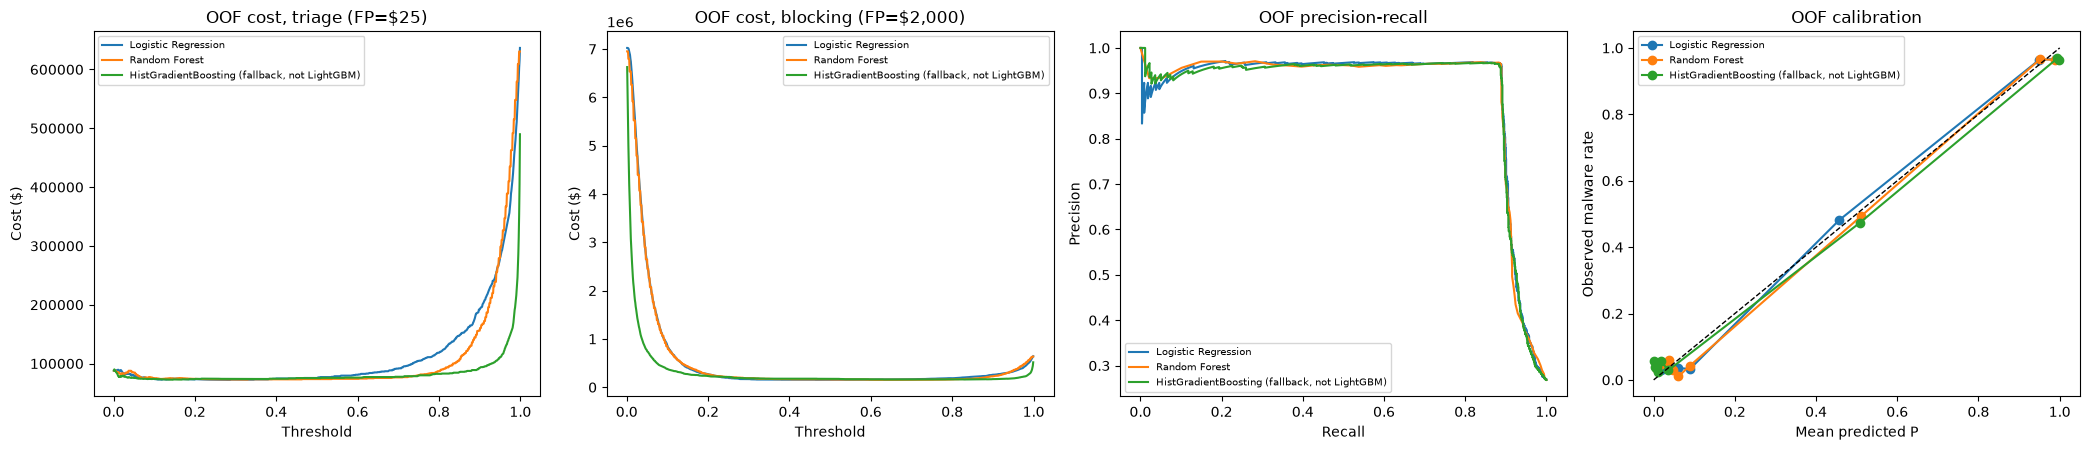

In [12]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
COST_FN = 500
COST_FP_TRIAGE, COST_FP_BLOCK = 25, 2000
COST_FP = COST_FP_TRIAGE
GRID = np.round(np.arange(.001, 1, .001), 3)

def counts(y, p, thr):
    y = np.asarray(y); pred = p >= thr
    tp, fp = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum())
    fn, tn = int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum())
    return tp, tn, fp, fn

def cost_curve(y, p, c_fp, c_fn=COST_FN, grid=GRID):
    y = np.asarray(y)[:, None]; pred = p[:, None] >= grid
    return c_fp * (pred & (y == 0)).sum(0) + c_fn * ((~pred) & (y == 1)).sum(0)

def best_threshold(y, p, c_fp):
    c = cost_curve(y, p, c_fp)
    tied = GRID[c == c.min()]          # middle of the tied thresholds: deterministic
    return float(tied[len(tied) // 2]), int(c.min())

def row(y, p, thr, c_fp):
    tp, tn, fp, fn = counts(y, p, thr)
    return {"Threshold": thr, "TP": tp, "TN": tn, "FP": fp, "FN": fn, "Alerts": tp + fp,
            "Precision": tp / (tp + fp) if tp + fp else np.nan, "Recall": tp / (tp + fn) if tp + fn else np.nan,
            "Cost ($)": c_fp * fp + COST_FN * fn}

# Development only: out-of-fold probabilities.
oof = {name: cross_val_predict(clone(candidates[name]), X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=1)[:, 1] for name in SHORTLIST}

frozen, dev_rows = {}, []
for name in SHORTLIST:
    t_tri, _ = best_threshold(y_dev, oof[name], COST_FP_TRIAGE)
    t_blk, _ = best_threshold(y_dev, oof[name], COST_FP_BLOCK)
    frozen[name] = {"triage": t_tri, "blocking": t_blk}
    dev_rows.append({"Model": name, "Scenario": "Triage (FP=$25)", **row(y_dev, oof[name], t_tri, COST_FP_TRIAGE)})
    dev_rows.append({"Model": name, "Scenario": "Blocking (FP=$2,000)", **row(y_dev, oof[name], t_blk, COST_FP_BLOCK)})
    dev_rows.append({"Model": name, "Scenario": "Triage cost at 0.50", **row(y_dev, oof[name], .5, COST_FP_TRIAGE)})
dev_table = pd.DataFrame(dev_rows).set_index(["Model", "Scenario"])
print("OOF development results; thresholds selected here and then frozen:")
display(dev_table.round(4))

# Final choice uses development OOF cost only, and is fixed before the lockbox is scored in the next cell.
FINAL_MODEL = min(SHORTLIST, key=lambda n: dev_table.loc[(n, "Triage (FP=$25)"), "Cost ($)"])
print("Final model (lowest OOF triage cost):", FINAL_MODEL, frozen[FINAL_MODEL])

print("Theoretical Bayes thresholds C_FP/(C_FP+C_FN):",
      {"triage": round(COST_FP_TRIAGE / (COST_FP_TRIAGE + COST_FN), 4), "blocking": round(COST_FP_BLOCK / (COST_FP_BLOCK + COST_FN), 4)})

# Stability of the optimum across development folds, and calibration of OOF scores.
stab = []
for name in SHORTLIST:
    for scen, c_fp in [("triage", COST_FP_TRIAGE), ("blocking", COST_FP_BLOCK)]:
        ts = [best_threshold(y_dev.iloc[va], oof[name][va], c_fp)[0] for _, va in cv.split(X_dev, y_dev)]
        stab.append({"Model": name, "Scenario": scen, "Fold min": min(ts), "Fold median": np.median(ts), "Fold max": max(ts)})
display(pd.DataFrame(stab).set_index(["Model", "Scenario"]).round(3))
print("OOF Brier score:", {n: round(brier_score_loss(y_dev, oof[n]), 4) for n in SHORTLIST})

fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for name in SHORTLIST:
    axes[0].plot(GRID, cost_curve(y_dev, oof[name], COST_FP_TRIAGE), label=name)
    axes[1].plot(GRID, cost_curve(y_dev, oof[name], COST_FP_BLOCK), label=name)
    pr, rc, _ = precision_recall_curve(y_dev, oof[name]); axes[2].plot(rc, pr, label=name)
    fr, mp = calibration_curve(y_dev, oof[name], n_bins=10, strategy="quantile"); axes[3].plot(mp, fr, marker="o", label=name)
axes[0].set(title="OOF cost, triage (FP=$25)", xlabel="Threshold", ylabel="Cost ($)")
axes[1].set(title="OOF cost, blocking (FP=$2,000)", xlabel="Threshold", ylabel="Cost ($)")
axes[2].set(title="OOF precision-recall", xlabel="Recall", ylabel="Precision")
axes[3].plot([0, 1], [0, 1], "k--", lw=1); axes[3].set(title="OOF calibration", xlabel="Mean predicted P", ylabel="Observed malware rate")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

Threshold  \
Model                                         Scenario                           
Logistic Regression                           Triage frozen              0.283   
                                              Triage cost at 0.50        0.500   
                                              Blocking frozen            0.499   
                                              Blocking cost at 0.50      0.500   
Random Forest                                 Triage frozen              0.327   
                                              Triage cost at 0.50        0.500   
                                              Blocking frozen            0.702   
                                              Blocking cost at 0.50      0.500   
HistGradientBoosting (fallback, not LightGBM) Triage frozen              0.146   
                                              Triage cost at 0.50        0.500   
                                              Blocking frozen            0.713   
                                              Blocking cost at 0.50      0.500   

                                                                      TP   TN  \
Model                                         Scenario                          
Logistic Regression                           Triage frozen          288  868   
                                              Triage cost at 0.50    286  870   
                                              Blocking frozen        286  870   
                                              Blocking cost at 0.50  286  870   
Random Forest                                 Triage frozen          288  866   
                                              Triage cost at 0.50    287  869   
                                              Blocking frozen        282  870   
                                              Blocking cost at 0.50  287  869   
HistGradientBoosting (fallback, not LightGBM) Triage frozen          288  856   
                                              Triage cost at 0.50    284  870   
                                              Blocking frozen        281  870   
                                              Blocking cost at 0.50  284  870   

                                                                     FP  FN  \
Model                                         Scenario                        
Logistic Regression                           Triage frozen          10  34   
                                              Triage cost at 0.50     8  36   
                                              Blocking frozen         8  36   
                                              Blocking cost at 0.50   8  36   
Random Forest                                 Triage frozen          12  34   
                                              Triage cost at 0.50     9  35   
                                              Blocking frozen         8  40   
                                              Blocking cost at 0.50   9  35   
HistGradientBoosting (fallback, not LightGBM) Triage frozen          22  34   
                                              Triage cost at 0.50     8  38   
                                              Blocking frozen         8  41   
                                              Blocking cost at 0.50   8  38   

                                                                     Alerts  \
Model                                         Scenario                        
Logistic Regression                           Triage frozen             298   
                                              Triage cost at 0.50       294   
                                              Blocking frozen           294   
                                              Blocking cost at 0.50     294   
Random Forest                                 Triage frozen             300   
                                              Triage cost at 0.50       296   
                                              

Bootstrap 95% intervals on the lockbox (sampling variation only), final model at its frozen triage threshold:
  Cost ($): 11775.000 to 22825.625
  Recall: 0.861 to 0.927
  Precision: 0.945 to 0.986
  Alerts per 1,200 files: 270.000 to 327.025


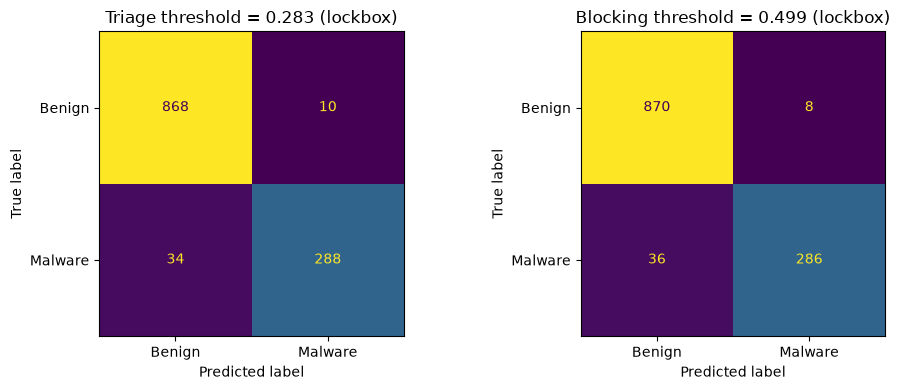

In [13]:
# LOCKBOX: thresholds were frozen in the previous cell. This cell is run once and nothing is retuned afterwards.
test_rows = []
for name in SHORTLIST:
    p = test_proba[name]
    test_rows.append({"Model": name, "Scenario": "Triage frozen", **row(y_test, p, frozen[name]["triage"], COST_FP_TRIAGE)})
    test_rows.append({"Model": name, "Scenario": "Triage cost at 0.50", **row(y_test, p, .5, COST_FP_TRIAGE)})
    test_rows.append({"Model": name, "Scenario": "Blocking frozen", **row(y_test, p, frozen[name]["blocking"], COST_FP_BLOCK)})
    test_rows.append({"Model": name, "Scenario": "Blocking cost at 0.50", **row(y_test, p, .5, COST_FP_BLOCK)})
test_table = pd.DataFrame(test_rows).set_index(["Model", "Scenario"])
display(test_table.round(4))

p_final, t_final = test_proba[FINAL_MODEL], frozen[FINAL_MODEL]["triage"]
boot_rng = np.random.default_rng(SEED); yt = y_test.to_numpy(); boot = []
for _ in range(2000):
    i = boot_rng.integers(0, len(yt), len(yt))
    tp, tn, fp, fn = counts(yt[i], p_final[i], t_final)
    boot.append((COST_FP_TRIAGE * fp + COST_FN * fn, tp / (tp + fn), tp / (tp + fp), tp + fp))
boot = np.array(boot)
print("Bootstrap 95% intervals on the lockbox (sampling variation only), final model at its frozen triage threshold:")
for j, lab in enumerate(["Cost ($)", "Recall", "Precision", "Alerts per 1,200 files"]):
    print(f"  {lab}: {np.percentile(boot[:, j], 2.5):.3f} to {np.percentile(boot[:, j], 97.5):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key, title in [(axes[0], "triage", "Triage threshold"), (axes[1], "blocking", "Blocking threshold")]:
    thr = frozen[FINAL_MODEL][key]
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_final >= thr).astype(int)), display_labels=["Benign", "Malware"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{title} = {thr:.3f} (lockbox)")
plt.tight_layout(); plt.show()

In [14]:
# Capacity check: indicative only. The test set is a synthetic sample, not a day of AtlasPay traffic.
DAILY_FILES, ALERT_TARGET = 12000, 120
t_final = frozen[FINAL_MODEL]["triage"]
tp, tn, fp, fn = counts(y_test, test_proba[FINAL_MODEL], t_final)
print(f"Lockbox alerts at frozen triage threshold: {tp + fp} of {len(y_test)} ({(tp + fp) / len(y_test):.2%})")
print(f"Naive arithmetic, NOT a forecast: {(tp + fp) / len(y_test) * DAILY_FILES:.0f} alerts per {DAILY_FILES} files at the synthetic prevalence")

# Development-only sensitivity: assumes class-conditional score distributions stay unchanged.
tp, tn, fp, fn = counts(y_dev, oof[FINAL_MODEL], t_final)
tpr, fpr = tp / (tp + fn), fp / (fp + tn)
print(f"OOF operating point: TPR={tpr:.4f}, FPR={fpr:.4f}")
sens = []
for prev in [.001, .005, .01, .02, .05, .10, .25]:
    alerts = DAILY_FILES * (prev * tpr + (1 - prev) * fpr)
    sens.append({"Assumed prevalence": prev, "Implied alerts/day": alerts, "Implied precision": prev * tpr / (prev * tpr + (1 - prev) * fpr), "Within 120?": alerts <= ALERT_TARGET})
display(pd.DataFrame(sens).set_index("Assumed prevalence").round(3))

# What a 1% alert budget would cost at the synthetic prevalence (development OOF).
t_cap = float(np.quantile(oof[FINAL_MODEL], 1 - ALERT_TARGET / DAILY_FILES))
print(f"Threshold giving a 1% alert rate on OOF scores: {t_cap:.4f}")
print(pd.Series(row(y_dev, oof[FINAL_MODEL], t_cap, COST_FP_TRIAGE)).round(4).to_string())

Lockbox alerts at frozen triage threshold: 298 of 1200 (24.83%)
Naive arithmetic, NOT a forecast: 2980 alerts per 12000 files at the synthetic prevalence
OOF operating point: TPR=0.8898, FPR=0.0140


,Implied alerts/day,Implied precision,Within 120?
Assumed prevalence,,,
0.001,177.984,0.060,False
0.005,220.027,0.243,False
0.010,272.579,0.392,False
0.020,377.685,0.565,False
0.050,693.002,0.770,False
0.100,1218.531,0.876,False
0.250,2795.116,0.955,False


Threshold giving a 1% alert rate on OOF scores: 0.9983
Threshold         0.9983
TP               44.0000
TN             3507.0000
FP                4.0000
FN             1245.0000
Alerts           48.0000
Precision         0.9167
Recall            0.0341
Cost ($)     622600.0000


## Answers: Part E (SOC cost model and thresholds)

**E1.** In analyst-assisted triage, an FP is a benign file that consumes analyst time and adds workflow friction. An FN is a malicious file that is not queued and can proceed to execution. In inline blocking, an FP stops a legitimate vendor update or payment-support executable, so its cost is an operational outage rather than review time.

**E2. Bayes threshold.** With calibrated probability p, flagging has expected cost (1 - p) C_FP and not flagging has expected cost p C_FN. Flag when (1 - p) C_FP < p C_FN, which gives **p > C_FP / (C_FP + C_FN)**.
- Triage: 25 / (25 + 500) = **0.0476**.
- Blocking: 2000 / (2000 + 500) = **0.8000**.

Assumptions: p is calibrated at deployment prevalence, costs are fixed per error and independent, correct decisions cost nothing, and there is no capacity limit.

**E3. Procedure.** I generated out-of-fold probabilities on the development set with the same 5 folds, evaluated thresholds 0.001 to 0.999 in steps of 0.001, took the minimum cost, and used the middle of any tied thresholds.

| Model | Triage threshold (OOF cost, USD) | Blocking threshold (OOF cost, USD) |
|---|---|---|
| Logistic Regression | 0.283 (72,225) | 0.499 (152,500) |
| Random Forest | 0.327 (72,800) | 0.702 (151,500) |
| Boosting fallback | 0.146 (72,550) | 0.713 (158,500) |

Logistic Regression was fixed as the final model from lowest OOF triage cost before lockbox scoring. The margin (USD 325 and 575, under 1%) is a practical tie, and simplicity supports the same choice.

**E4. Lockbox, evaluated once at frozen thresholds.**

| Model, scenario | Threshold | TP | TN | FP | FN | Precision | Recall | Cost (USD) | Same cost model at 0.50 (USD) |
|---|---|---|---|---|---|---|---|---|---|
| LR, triage | 0.283 | 288 | 868 | 10 | 34 | 0.9664 | 0.8944 | 17,250 | 18,200 |
| LR, blocking | 0.499 | 286 | 870 | 8 | 36 | 0.9728 | 0.8882 | 34,000 | 34,000 |
| RF, triage | 0.327 | 288 | 866 | 12 | 34 | 0.9600 | 0.8944 | 17,300 | 17,725 |
| RF, blocking | 0.702 | 282 | 870 | 8 | 40 | 0.9724 | 0.8758 | 36,000 | 35,500 |
| Boosting, triage | 0.146 | 288 | 856 | 22 | 34 | 0.9290 | 0.8944 | 17,550 | 19,200 |
| Boosting, blocking | 0.713 | 281 | 870 | 8 | 41 | 0.9723 | 0.8727 | 36,500 | 35,000 |

**Interpretation.** For Logistic Regression, the triage threshold trades 2 more FP for 2 fewer FN and saves USD 950 against 0.50. The bootstrap 95% interval for its lockbox cost is USD 11,775 to 22,826, and recall is 0.861 to 0.927, so differences between models are within sampling variation. On blocking, the frozen RF and boosting thresholds cost more than 0.50 on the lockbox. That is reported as obtained and nothing was retuned. Higher FP cost moves the threshold up because each flag must now be justified by stronger evidence.

**E5. Why theoretical and empirical thresholds differ.** Logistic Regression uses 0.283 against 0.0476 for triage, and 0.499 against 0.80 for blocking.
- **Calibration:** the Bayes rule needs exact probabilities. OOF calibration looks close to the diagonal (Brier 0.0405), but most scores are near 0 or 1, so the mid-range is thinly tested.
- **Finite samples:** cost curves are flat over a wide range. Logistic Regression's fold-level optimum runs from 0.087 to 0.434 for triage, and Random Forest's from 0.022 to 0.702.
- **Model limits and noise:** noisy labels and a limited score distribution mean few files fall between candidate thresholds, so the minimum is determined by a handful of them.

**Cost and prevalence limits.** The USD figures are planning assumptions, FN cost varies widely by incident, and the 26.85% prevalence does not represent the intended deployment.

## Phase 5 — Final architecture decision: CISO recommendation

Write a concise recommendation (approximately 1 page) answering:

1. What is AtlasPay’s business use case, what is the positive class, and why is the initial deployment analyst-assisted rather than autonomous blocking?
2. Which candidate do you recommend for the *perimeter scanning* scenario, and why?
3. What threshold do you recommend under the supplied cost assumptions?
4. What evidence supports the choice: PR-AUC, recall, precision, FP/FN, cost, latency and explainability?
5. Does the proposed alert volume appear compatible with the 120-alert/day planning target? What evidence is missing for a reliable daily forecast? What changes for inline blocking, where a false positive could interrupt payment-support operations?
6. What are the key risks before production: synthetic-to-real gap, label noise, prevalence shift, data drift, calibration, adversarial adaptation, analyst workflow and monitoring?


**Submission rule:** report the outputs you actually obtained. Do not copy expected results or describe synthetic patterns as universal malware signatures.

## Answers: Phase 5 (CISO recommendation)

*All values come from this notebook's run on synthetic data. Costs are the scenario's illustrative assumptions.*

**1. Use case, positive class and deployment mode**

AtlasPay wants to screen Windows PE files before they run, using static features. Files arrive from endpoints, vendor portals and support channels, at about 12,000 per day. The positive class is malware (`Is_Malware = 1`), and the unit of prediction is one file.

The first deployment is analyst-assisted for three reasons:
- A static score is not proof that a file is malicious.
- A false block could stop a legitimate vendor update or payment-support tool.
- Real prevalence, calibration and alert volume are still unknown.

**2. Recommended candidate for perimeter scanning**

I recommend Logistic Regression with median imputation and `RobustScaler`. It is not statistically better than the ensembles, but it matches them at the lowest complexity:

| Model | CV PR-AUC |
|---|---|
| Stacking | 0.9100 |
| Logistic Regression | 0.9080 |
| Random Forest | 0.9054 |
| HistGradientBoosting (LightGBM fallback) | 0.9042 |

The 0.0058 spread is well inside the fold standard deviation of about 0.02. Logistic Regression also has the lowest out-of-fold (OOF) triage cost, USD 72,225, against 72,550 for boosting and 72,800 for Random Forest. That margin is under 1%, so it is a practical tie. Its train-validation F1 gap is -0.0007. Random Forest stays as a challenger because it can capture feature interactions.

**3. Recommended threshold**

Use **0.283**, for analyst triage with FP = USD 25 and FN = USD 500. It was selected on development OOF predictions only, then frozen before the lockbox evaluation. The theoretical Bayes threshold is 0.0476, but the empirical cost curve is flat and the best threshold varied across folds from 0.087 to 0.434. It should be treated as a starting point to recalibrate on real data.

**4. Supporting evidence**

| Evidence | Observed result |
|---|---|
| CV performance | PR-AUC 0.9080, F1 0.9238 |
| Lockbox recall | 0.8944 (bootstrap 95% interval 0.861 to 0.927) |
| Lockbox precision | 0.9664 (bootstrap 95% interval 0.945 to 0.986) |
| Lockbox errors | 10 FP, 34 FN |
| Lockbox cost | USD 17,250, against 18,200 at threshold 0.50 (bootstrap 95% interval for 17,250: 11,775 to 22,826) |
| Latency, model call only | 1.29 ms per 1,000 files, 1.19 ms for one file; excludes PE parsing, feature extraction, I/O and service overhead |
| Explainability | Coefficients per IQR: `Export_Count` odds ratio 0.306, RWX section 2.360, abnormal timestamp 2.272 |

TreeSHAP was run on Random Forest, so it explains that challenger and not the recommended model. SHAP and coefficients describe model behaviour, not causality or proof of malware.

**5. Alert volume and inline blocking**

Compatibility with 120 alerts/day is **not demonstrated**:
- The lockbox produced 298 alerts in 1,200 files (24.83%), at a synthetic prevalence of about 27%. Scaling that to 2,980 per 12,000 is arithmetic, not a forecast.
- With OOF TPR 0.8898 and FPR 0.0140, implied volume is about 178/day at 0.1% prevalence and 273/day at 1%, assuming score distributions do not change. Both exceed the target.
- Part of that FPR may be label noise, which I did not verify.

A reliable forecast needs representative daily samples, real prevalence, de-duplication of repeated files, recalibration on AtlasPay telemetry and a shadow-mode capacity test.

For inline blocking, FP cost rises to USD 2,000. The selected threshold rises to 0.499, with 8 FP, 36 FN and a lockbox cost of USD 34,000. The fold range was 0.334 to 0.511. This does not justify enforcement. Blocking would need a separately validated threshold, an allowlist and exception path, tested rollback, and independent behavioural corroboration.

**6. Key risks before production**

- **Synthetic-to-real gap:** the dataset is neither AtlasPay telemetry nor the real EMBER benchmark, so these patterns are not universal malware signatures.
- **Label noise:** the generator flips 4% of labels. OOF errors (142 FN, 49 FP) are close to the expected flip counts (about 144 and 48), which suggests a noise ceiling, but this was not verified row by row.
- **Prevalence shift:** precision falls to an implied 0.243 at 0.5% prevalence and 0.060 at 0.1%.
- **Data drift:** new packers, compilers and vendor software will shift the features, so retraining triggers are needed.
- **Calibration:** OOF Brier score is 0.0405, but most scores sit near 0 or 1, so mid-range probabilities are thinly tested and must be rechecked at real prevalence.
- **Adversarial adaptation:** attackers can manipulate static features such as exports, imports, section structure and signatures. Static scoring needs behavioural analysis alongside it.
- **Analyst workflow:** queue handling, triage quality, feedback labels and alert fatigue are untested.
- **Monitoring:** track alert volume, score distribution, parser failures (the 99999.0 sentinel), analyst-confirmed precision, missed-malware reviews and drift, with a defined rollback path.

**Decision:** run Logistic Regression at 0.283 in shadow mode first, then move to analyst-assisted triage if real-world alert volume, calibration and sandbox-corroborated performance are acceptable. Autonomous blocking remains a separate, later decision.


## Answers: Part F (operational feasibility)

**F1. Latency.** 12,000 files/day averages 0.14 files/s. The Logistic Regression model call took 1.29 ms per 1,000 files, and 1.19 ms for one file, far above that average need. **Included:** in-process `predict_proba` on an already parsed feature table on this 8-logical-CPU laptop. **Excluded:** PE parsing, feature extraction, I/O, queueing, network and service overhead, and burst load. End-to-end throughput cannot be inferred from this measurement.

**F2. Capacity.** The notebook does **not** demonstrate that the SOC can stay below 120 alerts/day. The lockbox gives 298 alerts in 1,200 files (24.83%), which reflects its synthetic 26.83% prevalence. Multiplying to 2,980 per 12,000 is arithmetic and not a forecast. Using OOF TPR 0.8898 and FPR 0.0140, implied alerts are about 178/day at 0.1% prevalence and 273/day at 1%, assuming score distributions are unchanged. Those figures all exceed 120, although part of the 1.40% FPR may be label noise (hypothesis from Part C). A reliable forecast requires representative daily samples, production prevalence, de-duplication of repeated files, recalibration and a capacity test.

**F3. Recommended initial role.** Shadow mode first, with analyst-assisted triage as the target role, and no autonomous blocking. Detection evidence is promising on synthetic data, but alert volume, real prevalence and calibration are unknown.

**F4. Conditions before any autonomous blocking pilot.**
1. Representative temporal evaluation on AtlasPay telemetry, with training strictly before testing.
2. Calibration verified at production prevalence, and an empirically justified blocking threshold.
3. Tested rollback, plus an allowlist and exception path for business-critical vendor software.
4. Analyst review of blocking candidates, showing an acceptable false-block rate over a sustained shadow period.
5. Drift and adversarial-robustness monitoring, with retraining criteria.
6. Independent behavioural corroboration (sandbox or EDR) before a block is enforced.

---

# Executive decision memo

**To:** CISO, AtlasPay Services | **From:** Applied ML team | **Subject:** Pre-execution PE screening, first deployment

**Scope warning.** Every result below comes from a synthetic, EMBER-inspired teaching dataset. It is not AtlasPay telemetry and is not evidence of production performance. Cost figures are illustrative planning assumptions.

**Recommendation.** Run **Logistic Regression** (median imputation, RobustScaler) at a frozen threshold of **0.283** in **shadow mode**, then move to **analyst-assisted triage** if the validation gate below is met. The positive class is malware. The model recommends files for review. It does not establish that a file is malicious and it must not block files.

**Evidence (observed).**
- **Discrimination:** CV PR-AUC 0.9080 and F1 0.9238, with no train-validation gap (-0.0007). Stacking, Random Forest and the boosting fallback are within 0.0058 PR-AUC, inside fold variation.
- **Lockbox at 0.283:** recall 0.8944, precision 0.9664, 10 FP, 34 FN, cost USD 17,250 against 18,200 at threshold 0.50. Bootstrap 95% interval for recall: 0.861 to 0.927.
- **Latency:** about 1.2 ms per model call for a single file, model only.
- **Explainability:** coefficients are directly reviewable. `Export_Count` is the strongest (odds ratio 0.306 per IQR), followed by RWX sections (2.360) and abnormal timestamps (2.272). Random Forest stays as a challenger with TreeSHAP, because it captures interactions that the linear model misses in rare cases such as row 5115.

**Why not autonomous blocking.** With a false-positive cost of USD 2,000, a block interrupts payment-support operations. Lockbox cost at the blocking threshold is USD 34,000 with 8 FP and 36 FN, which is not acceptable evidence for enforcement. The blocking threshold also varied across folds (0.334 to 0.511).

**Main limitations and risks.**
- **Synthetic-to-real gap and label noise:** the 4% generated label flips probably cap measured performance, and real noise will differ.
- **Prevalence shift and calibration:** precision drops sharply at low base rates (0.060 at 0.1% under stated assumptions).
- **Capacity:** the 120-alert/day target is unproven and implied volumes exceed it.
- **Drift and adversarial adaptation:** attackers can change static features, and new packers and vendors will shift distributions.
- **Analyst workflow:** queue handling and analyst feedback quality are untested.

**Next validation gate.** Over a defined shadow period on real AtlasPay files, with no effect on operations, measure daily alert volume against 120, recalibrate on real prevalence, confirm precision and recall with sandbox-corroborated analyst labels, and test drift monitoring. Promote to analyst-assisted triage only if those results are acceptable. Autonomous blocking remains a separate later decision, subject to the conditions in F4.